In [ ]:
import pandas as pd

data = pd.read_csv('/content/ai4i2020.csv')

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
print(data["Machine failure"].value_counts())

Machine failure
0    9661
1     339
Name: count, dtype: int64


In [ ]:
print(data.isnull().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [ ]:
X = data.drop(columns=[
    "UDI", "Product ID", "Machine failure",
    "TWF", "HDF", "PWF", "OSF", "RNF"
])

y = data["Machine failure"]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Target: Machine failure


In [ ]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(X, columns=["Type"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("Baseline model training complete!")

Baseline model training complete!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.978

Confusion Matrix:
[[1911   21]
 [  23   45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.68      0.66      0.67        68

    accuracy                           0.98      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.98      0.98      0.98      2000



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Accuracy: 0.981

Confusion Matrix:
[[1930    2]
 [  36   32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.94      0.47      0.63        68

    accuracy                           0.98      2000
   macro avg       0.96      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training complete!")

Logistic Regression training complete!


In [ ]:
lr_pred = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

Accuracy: 0.8245

Confusion Matrix:
[[1593  339]
 [  12   56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, lr_pred)
    ],
    "Failure Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, lr_pred, zero_division=0)
    ],
    "Failure Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, lr_pred, zero_division=0)
    ],
    "Failure F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, lr_pred, zero_division=0)
    ]
})

results.round(3)

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1-score
0,Decision Tree,0.978,0.682,0.662,0.672
1,Random Forest,0.981,0.941,0.471,0.627
2,Logistic Regression,0.824,0.142,0.824,0.242


In [ ]:
dt_tuned = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

dt_tuned.fit(X_train, y_train)

dt_pred = dt_tuned.predict(X_test)

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))
print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Accuracy: 0.929

Confusion Matrix:
[[1798  134]
 [   8   60]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1932
           1       0.31      0.88      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.91      0.71      2000
weighted avg       0.97      0.93      0.94      2000



In [15]:
comparison = pd.DataFrame({
    "Model": ["Original Decision Tree", "Tuned Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Failure Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, dt_pred, zero_division=0)
    ],
    "Failure Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, dt_pred, zero_division=0)
    ],
    "Failure F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, dt_pred, zero_division=0)
    ]
})

comparison.round(3)

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1-score
0,Original Decision Tree,0.978,0.682,0.662,0.672
1,Tuned Decision Tree,0.929,0.309,0.882,0.458


In [16]:
rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_tuned.fit(X_train, y_train)

rf_tuned_pred = rf_tuned.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_tuned_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_tuned_pred, zero_division=0))

Accuracy: 0.9725

Confusion Matrix:
[[1892   40]
 [  15   53]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.57      0.78      0.66        68

    accuracy                           0.97      2000
   macro avg       0.78      0.88      0.82      2000
weighted avg       0.98      0.97      0.97      2000



In [17]:
final_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_tuned_pred)
    ],
    "Failure Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_tuned_pred)
    ],
    "Failure Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_tuned_pred)
    ],
    "Failure F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_tuned_pred)
    ]
})

final_comparison.round(3)

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1-score
0,Decision Tree,0.978,0.682,0.662,0.672
1,Random Forest,0.981,0.941,0.471,0.627
2,Logistic Regression,0.824,0.142,0.824,0.242
3,Tuned Random Forest,0.972,0.570,0.779,0.658


In [18]:
X_train2, X_val, y_train2, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training records:", len(X_train2))
print("Validation records:", len(X_val))
print("Final test records:", len(X_test))

Training records: 6400
Validation records: 1600
Final test records: 2000


In [19]:
rf_validation = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_validation.fit(X_train2, y_train2)

val_pred = rf_validation.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, val_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_pred))
print("\nClassification report:")
print(classification_report(y_val, val_pred, zero_division=0))

Validation accuracy: 0.965625

Confusion matrix:
[[1506   40]
 [  15   39]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1546
           1       0.49      0.72      0.59        54

    accuracy                           0.97      1600
   macro avg       0.74      0.85      0.78      1600
weighted avg       0.97      0.97      0.97      1600



In [20]:
from sklearn.metrics import confusion_matrix, classification_report

val_prob = rf_validation.predict_proba(X_val)[:, 1]

threshold = 0.60
val_pred_threshold = (val_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_threshold))
print("\nClassification Report:")
print(classification_report(
    y_val, val_pred_threshold, zero_division=0
))

Threshold: 0.6

Confusion Matrix:
[[1518   28]
 [  18   36]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1546
           1       0.56      0.67      0.61        54

    accuracy                           0.97      1600
   macro avg       0.78      0.82      0.80      1600
weighted avg       0.97      0.97      0.97      1600



In [21]:
threshold = 0.70
val_pred_threshold = (val_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_threshold))
print("\nClassification Report:")
print(classification_report(
    y_val, val_pred_threshold, zero_division=0
))

Threshold: 0.7

Confusion Matrix:
[[1535   11]
 [  27   27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1546
           1       0.71      0.50      0.59        54

    accuracy                           0.98      1600
   macro avg       0.85      0.75      0.79      1600
weighted avg       0.97      0.98      0.97      1600



In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

for t in [0.50, 0.60, 0.70]:
    pred = (val_prob >= t).astype(int)
    print(
        f"Threshold={t:.2f} | "
        f"Precision={precision_score(y_val, pred):.2f} | "
        f"Recall={recall_score(y_val, pred):.2f} | "
        f"F1={f1_score(y_val, pred):.2f}"
    )

Threshold=0.50 | Precision=0.49 | Recall=0.72 | F1=0.59
Threshold=0.60 | Precision=0.56 | Recall=0.67 | F1=0.61
Threshold=0.70 | Precision=0.71 | Recall=0.50 | F1=0.59


In [23]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Train the chosen model on the full training set
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
final_model.fit(X_train, y_train)

# Evaluate on the test set using threshold 0.60
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.60).astype(int)

print("Accuracy:", accuracy_score(y_test, test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, test_pred))
print("Classification Report:\n", classification_report(y_test, test_pred, zero_division=0))

Accuracy: 0.9765
Confusion Matrix:
 [[1903   29]
 [  18   50]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.63      0.74      0.68        68

    accuracy                           0.98      2000
   macro avg       0.81      0.86      0.83      2000
weighted avg       0.98      0.98      0.98      2000



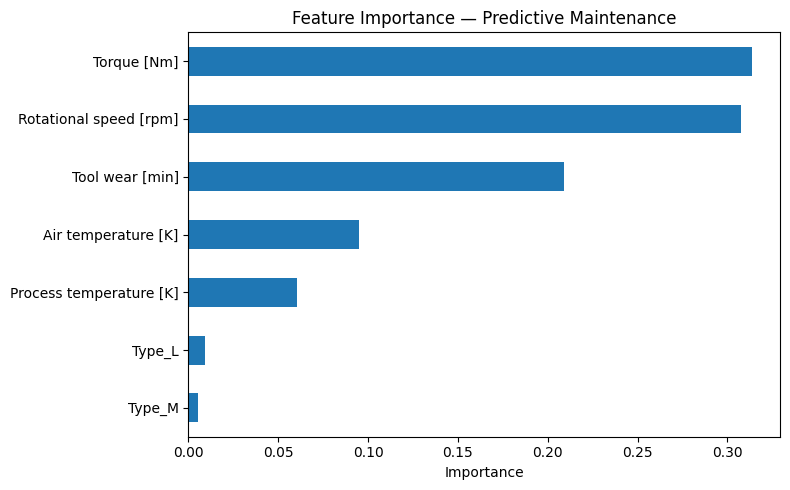

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance — Predictive Maintenance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


### Key Findings

- Trained and compared Decision Tree, Random Forest, and Logistic Regression models using the AI4I 2020 predictive maintenance dataset.
- Selected a Random Forest model with a classification threshold of 0.60.
- Achieved **97.65% accuracy**, **73.5% recall**, and **63.3% precision** for machine failures on the test set.
- Detected 50 of 68 failures, with 18 missed failures and 29 false alarms.
- Feature-importance analysis identified torque, rotational speed, and tool wear as the model's three most influential features.
- Explored the trade-off between detecting more failures and reducing false alarms by adjusting the classification threshold.

**Limitation:** This project uses a benchmark dataset, and its results do not establish performance on real industrial equipment.